# Pronóstico de Demanda Horaria de Taxis en Aeropuertos — Sweet Lift Taxi

## Contexto e Introducción
La compañía **Sweet Lift Taxi** ha recopilado un registro histórico detallado sobre los pedidos de taxis realizados en los aeropuertos entre marzo y agosto de 2018 (en intervalos de 10 minutos). Durante las horas de mayor afluencia de vuelos y pasajeros, la demanda de vehículos aumenta considerablemente y supera la oferta disponible. 

Para optimizar la logística operativa y atraer a más conductores hacia los aeropuertos justo antes de los momentos de mayor congestión, la empresa necesita anticipar el volumen de solicitudes a corto plazo mediante técnicas de aprendizaje automático aplicadas a **series temporales**.

---

## Objetivos del proyecto

### Objetivo general
* Desarrollar y validar un modelo de aprendizaje automático capaz de **predecir la cantidad de pedidos de taxis para la próxima hora**, alcanzando un Error Cuadrático Medio Raíz (**RECM**) **no superior a 48** en el conjunto de prueba.

### Objetivos específicos
1. **Preparar y estructurar la serie temporal:** Validar la integridad cronológica de los datos históricos y agrupar los registros mediante un remuestreo por intervalos de **1 hora**.
2. **Analizar patrones temporales:** Identificar tendencias a largo plazo, ciclos de estacionalidad (diaria y semanal) y evaluar la estacionariedad de la serie.
3. **Construir características temporales (*Feature Engineering*):** Extraer variables de calendario, desfases horarios (*lags*) y medias móviles desplazadas sin introducir fuga de datos (*data leakage*).
4. **Entrenar y optimizar múltiples modelos:** Comparar diferentes familias de algoritmos (modelos lineales, ensambles basados en árboles y *gradient boosting*) ajustando sus hiperparámetros mediante validación cruzada temporal.
5. **Evaluar en datos no vistos:** Medir el desempeño final sobre el 10 % más reciente de los datos, contrastarlo frente a una línea base ingenua y emitir una recomendación accionable para el negocio.

---

## Plan de trabajo

El desarrollo del proyecto se organiza en cuatro etapas secuenciales:

1. **Preparación de los datos:**
   * Carga del dataset (`taxi.csv`), configuración del índice de fecha y hora (`DatetimeIndex`), verificación de valores ausentes y orden cronológico, y remuestreo horario (`1h`).
2. **Análisis exploratorio de la serie temporal:**
   * Cálculo de estadísticas descriptivas, evaluación de estacionariedad visual (media y desviación estándar móviles de 24 horas) y estadística mediante la prueba de **Dickey-Fuller Aumentada (`adfuller`)**, descomposición estacional (`seasonal_decompose`) e identificación de horas pico reales y días de mayor demanda.
3. **Formación y ajuste de modelos:**
   * Creación de la función `make_features()`, división cronológica en conjuntos de entrenamiento (**90 %**) y prueba (**10 %**), y optimización de **Regresión Lineal**, **Random Forest** y **LightGBM** utilizando `TimeSeriesSplit`.
4. **Prueba y conclusiones:**
   * Evaluación del RECM en el conjunto de prueba frente a un modelo de referencia ingenuo, visualización de valores reales vs. predicciones y redacción de las conclusiones finales.


## Preparación y estructuración de la serie temporal.
En esta primera etapa se importan las librerías necesarias y se carga el conjunto de datos históricos de pedidos de taxis (`/datasets/taxi.csv`), configurando la columna de fecha y hora como el índice temporal de la tabla.

Posteriormente, se llevan a cabo las siguientes verificaciones y transformaciones iniciales:
* Comprobar el tipo de datos y la presencia de valores ausentes.
* Verificar que los registros estén ordenados de forma estrictamente cronológica.
* Realizar el **remuestreo por intervalos de 1 hora** sumando el total de pedidos registrados en cada hora, preparando así la serie temporal para su análisis y modelado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor

In [2]:
# Carga del dataset con índice temporal
try:
    data = pd.read_csv('/datasets/taxi.csv', index_col=[0], parse_dates=[0])
except FileNotFoundError:
    data = pd.read_csv('taxi.csv', index_col=[0], parse_dates=[0])

# Verificación de orden cronológico y valores ausentes
print("¿Índice ordenado cronológicamente?:", data.index.is_monotonic_increasing)
data.sort_index(inplace=True)
print("Valores ausentes antes del remuestreo:", data.isna().sum().to_dict())

print("\n--- Información inicial de la tabla ---")
data.info()

# Remuestreo por 1 hora sumando los pedidos
data = data.resample('1h').sum()

print("\n--- Información después del remuestreo a 1 hora ---")
data.info()
print("\nPrimeras 5 filas remuestreadas:")
print(data.head())


¿Índice ordenado cronológicamente?: True
Valores ausentes antes del remuestreo: {'num_orders': 0}

--- Información inicial de la tabla ---
<class 'pandas.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB

--- Información después del remuestreo a 1 hora ---
<class 'pandas.DataFrame'>
DatetimeIndex: 4416 entries, 2018-03-01 00:00:00 to 2018-08-31 23:00:00
Freq: h
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  4416 non-null   int64
dtypes: int64(1)
memory usage: 69.0 KB

Primeras 5 filas remuestreadas:
                     num_orders
datetime                       
2018-03-01 00:00:00         124
2018-03-01 01:00:00          85
2018-03-01 02:00:00          71
2018-03-01 03:00:00          66

### Observaciones sobre la preparación de datos
* El conjunto original contiene **26,496 registros** tomados cada 10 minutos, desde el `2018-03-01 00:00:00` hasta el `2018-08-31 23:50:00`.
* No existen valores ausentes y los registros ya se encontraban ordenados cronológicamente (`is_monotonic_increasing = True`).
* Tras realizar el remuestreo por intervalos de **1 hora** (`resample('1h').sum()`), se obtiene una serie temporal continua de **4,416 observaciones** sin datos faltantes.

## Análisis exploratorio
En esta etapa se realiza un análisis exploratorio de la serie temporal remuestreada por hora para comprender su comportamiento histórico y detectar patrones clave antes del modelado.

Para ello, se llevan a cabo las siguientes acciones:
* Obtener las **estadísticas descriptivas** principales del número de pedidos por hora.
* Evaluar la **estacionariedad** de la serie mediante el cálculo y visualización de la media móvil y la desviación estándar móvil (24 horas), respaldada por la prueba formal de **Dickey-Fuller Aumentada (ADF)**.
* Descomponer la serie en sus componentes de **tendencia, estacionalidad y residuos** (`seasonal_decompose`), realizando un acercamiento a los primeros días para identificar las horas pico y valle.
* Analizar la distribución promedio real de pedidos según la **hora del día** y el **día de la semana**.


--- Estadísticas descriptivas por hora ---
        num_orders
count  4416.000000
mean     84.422781
std      45.023853
min       0.000000
25%      54.000000
50%      78.000000
75%     107.000000
max     462.000000

--- Prueba de Dickey-Fuller Aumentada (ADF) ---
Estadístico ADF: -3.0689
Valor p (p-value): 0.0289
Conclusión estadística: Estacionaria (p < 0.05)


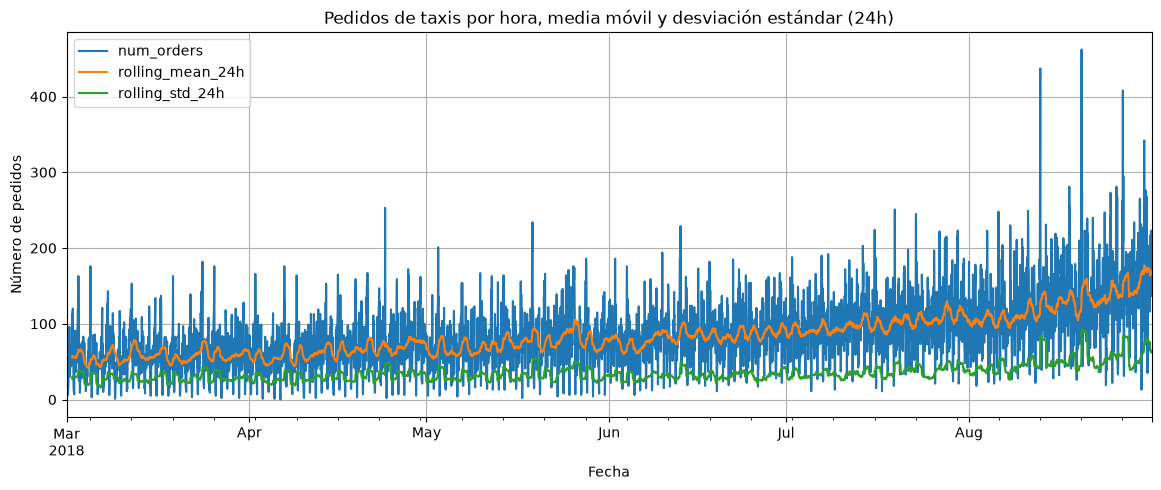

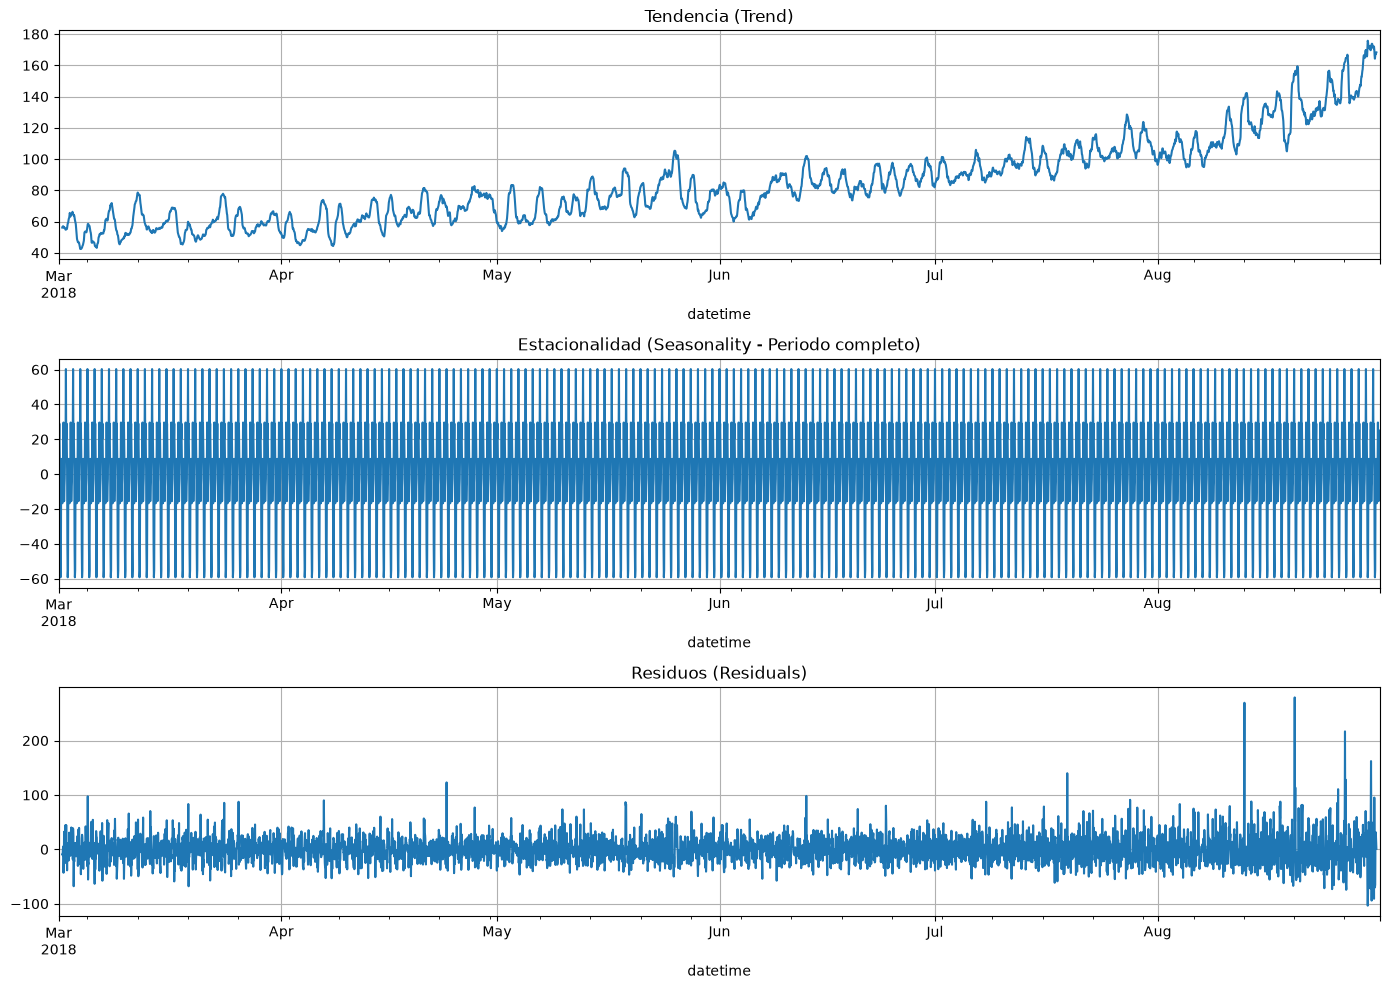

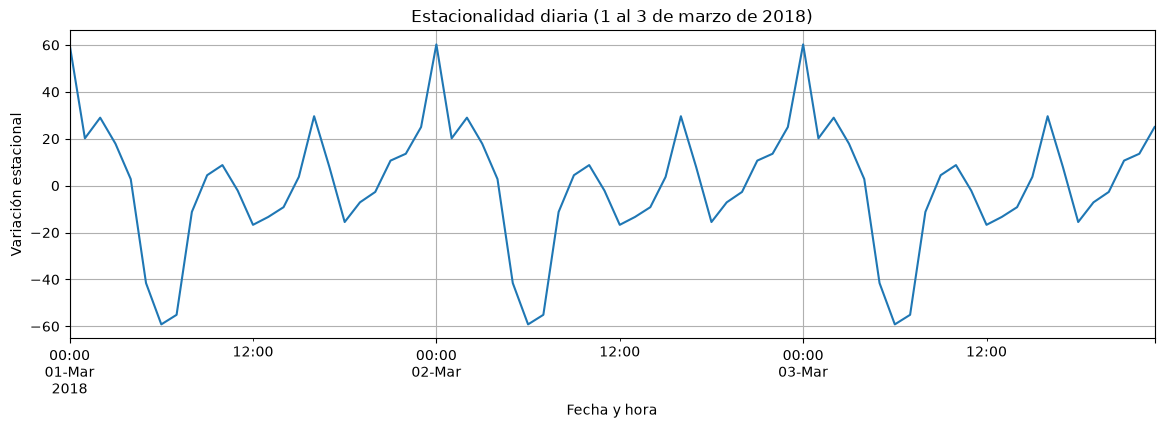

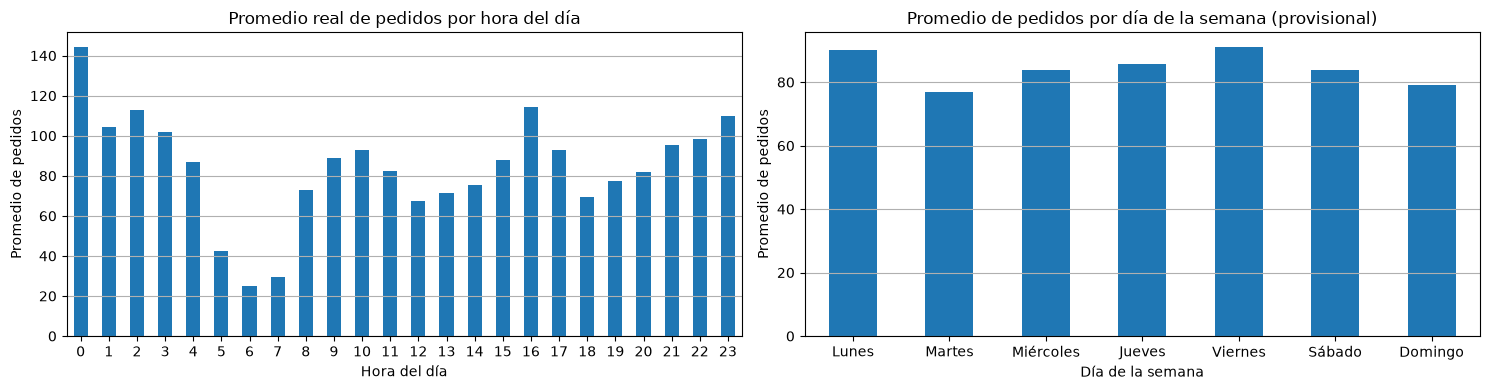

In [3]:
# 1. Estadísticas descriptivas generales
print("--- Estadísticas descriptivas por hora ---")
print(data.describe())

# 2. Prueba formal de estacionariedad: Dickey-Fuller Aumentada (ADF)
adf_stat, p_value, _, _, _, _ = adfuller(data['num_orders'], result_object=False)
print("\n--- Prueba de Dickey-Fuller Aumentada (ADF) ---")
print(f"Estadístico ADF: {adf_stat:.4f}")
print(f"Valor p (p-value): {p_value:.4f}")
print("Conclusión estadística:", "Estacionaria (p < 0.05)" if p_value < 0.05 else "No estacionaria (p >= 0.05)")

# 3. Gráfico de la serie temporal con media móvil y desviación estándar móvil (24h)
analysis_df = data.copy()
analysis_df['rolling_mean_24h'] = analysis_df['num_orders'].rolling(24).mean()
analysis_df['rolling_std_24h'] = analysis_df['num_orders'].rolling(24).std()

analysis_df.plot(figsize=(14, 5), title='Pedidos de taxis por hora, media móvil y desviación estándar (24h)')
plt.xlabel('Fecha')
plt.ylabel('Número de pedidos')
plt.grid(True)
plt.show()

# 4. Descomposición de la serie temporal
decomposed = seasonal_decompose(data)

plt.figure(figsize=(14, 10))
plt.subplot(311)
decomposed.trend.plot(ax=plt.gca(), title='Tendencia (Trend)')
plt.grid(True)

plt.subplot(312)
decomposed.seasonal.plot(ax=plt.gca(), title='Estacionalidad (Seasonality - Periodo completo)')
plt.grid(True)

plt.subplot(313)
decomposed.resid.plot(ax=plt.gca(), title='Residuos (Residuals)')
plt.grid(True)

plt.tight_layout()
plt.show()

# Acercamiento de 3 días al componente estacional
plt.figure(figsize=(14, 4))
decomposed.seasonal['2018-03-01':'2018-03-03'].plot(ax=plt.gca(), title='Estacionalidad diaria (1 al 3 de marzo de 2018)')
plt.xlabel('Fecha y hora')
plt.ylabel('Variación estacional')
plt.grid(True)
plt.show()

# 5. Promedio real de pedidos por hora del día (0 a 23h) y por día de la semana
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

hourly_orders = data.groupby(data.index.hour)['num_orders'].mean()
hourly_orders.plot(kind='bar', ax=axes[0], title='Promedio real de pedidos por hora del día')
axes[0].set_xlabel('Hora del día')
axes[0].set_ylabel('Promedio de pedidos')
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y')

weekday_orders = data.groupby(data.index.dayofweek)['num_orders'].mean()
weekday_orders.index = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
weekday_orders.plot(kind='bar', ax=axes[1], title='Promedio de pedidos por día de la semana (provisional)')
axes[1].set_xlabel('Día de la semana')
axes[1].set_ylabel('Promedio de pedidos')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y')

plt.tight_layout()
plt.show()


### Observaciones del análisis exploratorio
* **Estadísticas generales:** El promedio de pedidos por hora es de **84.42** (mediana de **78**), con una desviación estándar de **45.02** y un máximo de **462 pedidos** en una hora (registrado en agosto).
* **Evaluación de estacionariedad (visual vs. prueba formal ADF):**
  * **Análisis visual:** Tanto la media móvil de 24 horas como el componente de tendencia (`Trend`) muestran un **crecimiento sostenido** desde marzo (~55–60 pedidos/hora) hasta finales de agosto (~160–170 pedidos/hora), mientras que la desviación estándar móvil **casi se duplica** en agosto. Esto indica que la serie **no es estacionaria en sentido estricto** (su media y varianza cambian en el tiempo).
  * **Prueba de Dickey-Fuller Aumentada (ADF):** Arroja un estadístico de **`-3.0689`** y un **`p-value = 0.0289`**. Al ser menor a `0.05` (pero mayor al umbral estricto de `0.01`), se rechaza la presencia de raíz unitaria al 5 % de significancia: la serie es **estacionaria alrededor de una tendencia determinista (*trend-stationary*)** debido a su fuerte reversión al ciclo diario, aunque requiere variables de tendencia/desfases para modelar su crecimiento.


## Formación y ajuste de Modelos
En esta sección se preparan las variables predictoras y se entrenan distintos algoritmos de aprendizaje automático para pronosticar la demanda de taxis en la próxima hora.

El proceso seguirá estos pasos:
* Crear la función `make_features()` para generar características de calendario (`month`, `day`, `dayofweek`, `hour`), **24 desfases horarios** (`lag_1` a `lag_24`) y una **media móvil desplazada de 24 horas** (`rolling_mean`) que evite la fuga de datos.
* Dividir la serie de forma cronológica (`shuffle=False`) destinando el **90 % inicial para entrenamiento** y reservando el **10 % final para prueba**, tal como exigen las instrucciones del proyecto.
* Entrenar y ajustar hiperparámetros mediante un flujo modular con validación cruzada temporal (`TimeSeriesSplit`) comparando tres familias de modelos: **Regresión Lineal**, **Random Forest Regressor** y **LightGBM Regressor**.


In [4]:
# 1. Función para ingeniería de características sin fuga de datos
def make_features(df, max_lag, rolling_mean_size):
    df_features = df.copy()
    df_features['month'] = df_features.index.month
    df_features['day'] = df_features.index.day
    df_features['dayofweek'] = df_features.index.dayofweek
    df_features['hour'] = df_features.index.hour
    
    for lag in range(1, max_lag + 1):
        df_features[f'lag_{lag}'] = df_features['num_orders'].shift(lag)
        
    df_features['rolling_mean'] = df_features['num_orders'].shift().rolling(rolling_mean_size).mean()
    return df_features

# Creamos características usando 24 desfases (1 día completo) y media móvil de 24 horas
data_features = make_features(data, max_lag=24, rolling_mean_size=24)

# 2. División en entrenamiento (90%) y prueba (10%) respetando el orden cronológico
train, test = train_test_split(data_features, shuffle=False, test_size=0.1)
train = train.dropna()

features_train = train.drop(['num_orders'], axis=1)
target_train = train['num_orders']
features_test = test.drop(['num_orders'], axis=1)
target_test = test['num_orders']

print(f"Tamaño de entrenamiento: {features_train.shape}, Tamaño de prueba: {features_test.shape}\n")

# 3. Configuración de validación cruzada temporal y diccionario de modelos con grillas ampliadas
tscv = TimeSeriesSplit(n_splits=5)

models_config = {
    'Regresión Lineal': {
        'model': LinearRegression(),
        'params': {}
    },
    'Random Forest': {
        'model': RandomForestRegressor(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': list((100, 150, 200)),
            'max_depth': list((10, 15, 20, None)),
            'min_samples_split': list((2, 5))
        }
    },
    'LightGBM': {
        'model': LGBMRegressor(random_state=42, verbose=-1, n_jobs=1),
        'params': {
            'n_estimators': list((100, 150, 200, 250)),
            'learning_rate': list((0.03, 0.05, 0.1)),
            'num_leaves': list((15, 31, 50))
        }
    }
}

# Entrenamiento y optimización sin duplicación de código
best_models = {}

for name, config in models_config.items():
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=tscv,
        scoring='neg_root_mean_squared_error',
        n_jobs=1
    )
    grid.fit(features_train, target_train)
    best_models[name] = grid.best_estimator_
    
    print(f"RECM Validación Cruzada - {name}: {-grid.best_score_:.2f}")
    if config['params']:
        print(f"Mejores hiperparámetros {name}: {grid.best_params_}")
    print("-" * 50)


Tamaño de entrenamiento: (3950, 29), Tamaño de prueba: (442, 29)

RECM Validación Cruzada - Regresión Lineal: 26.94
--------------------------------------------------
RECM Validación Cruzada - Random Forest: 25.13
Mejores hiperparámetros Random Forest: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
--------------------------------------------------
RECM Validación Cruzada - LightGBM: 24.77
Mejores hiperparámetros LightGBM: {'learning_rate': 0.05, 'n_estimators': 200, 'num_leaves': 15}
--------------------------------------------------


### Observaciones del entrenamiento y validación
* Se creó la función `make_features()` para extraer variables de calendario (`month`, `day`, `dayofweek`, `hour`), **24 desfases horarios** (`lag_1` a `lag_24`) y la **media móvil desplazada de 24 horas** (`rolling_mean`), evitando la fuga de datos.
* Se dividió el conjunto de forma cronológica (`shuffle=False`) respetando el **10 % para prueba** (442 registros) y **90 % para entrenamiento** (3,950 registros tras eliminar los valores ausentes iniciales).
* Utilizando un bucle modular con validación cruzada temporal (`TimeSeriesSplit` con 5 particiones) y grillas ampliadas de hiperparámetros, se compararon tres familias de modelos:
  * **Regresión Lineal (Baseline):** RECM de **26.94**.
  * **Random Forest Regressor** (`n_estimators=200`, `min_samples_split=5`, `max_depth=None`): RECM de **25.13**.
  * **LightGBM Regressor** (`learning_rate=0.05`, `n_estimators=200`, `num_leaves=15`): RECM de **24.77** (mejor modelo en validación).

## Prueba (Evaluación del RECM en el conjunto de Prueba)
En esta última etapa se evalua el desempeño final de los modelos entrenados utilizando el **conjunto de prueba (10 % final)** reservado anteriormente, verificando que la métrica **RECM** no supere el umbral máximo permitido de **48**.

Para validar la calidad del pronóstico, se realiza lo siguiente:
* Comparar los modelos entrenados frente a una **línea base ingenua** (predicción igual al valor de la hora anterior) mediante una función de evaluación reutilizable.
* Visualizar gráficamente los **pedidos reales frente a las predicciones del mejor modelo** durante los últimos 7 días del periodo de prueba.
* Exponer las **conclusiones generales** y la recomendación final para Sweet Lift Taxi.

RECM en prueba - Modelo Ingenuo (hora anterior): 58.86

RECM en prueba - Regresión Lineal: 45.81
RECM en prueba - Random Forest: 43.46
RECM en prueba - LightGBM: 40.83


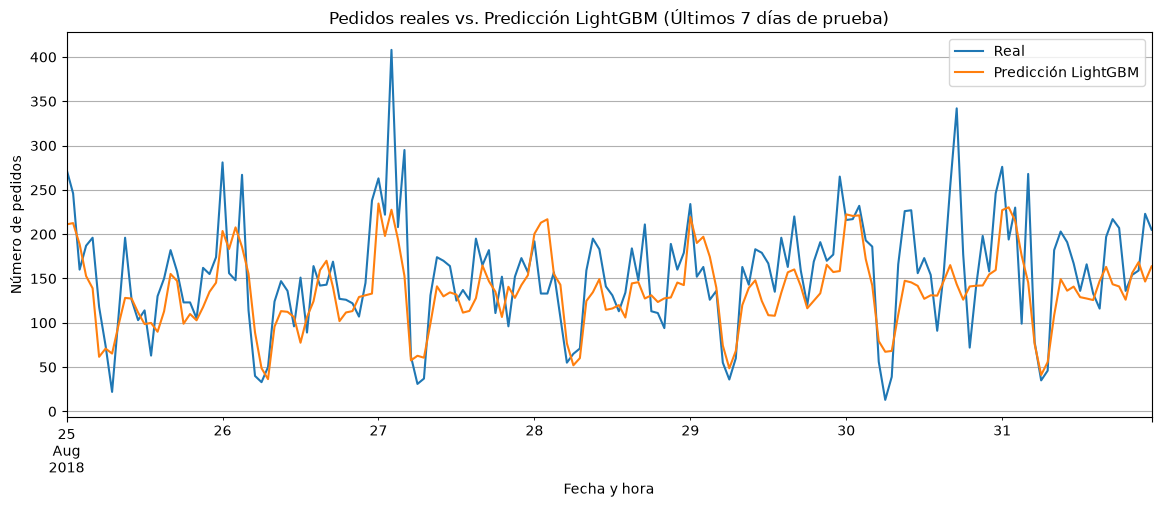

In [5]:
# Función para evaluar y mostrar el RECM en el conjunto de prueba sin duplicar código
def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)
    rmse = mean_squared_error(y_test, predictions) ** 0.5
    print(f"RECM en prueba - {model_name}: {rmse:.2f}")
    return predictions, rmse

# Evaluación de línea base ingenua (predicción igual a la hora anterior)
pred_previous = target_test.shift().fillna(target_train.iloc[-1])
rmse_baseline = mean_squared_error(target_test, pred_previous) ** 0.5
print(f"RECM en prueba - Modelo Ingenuo (hora anterior): {rmse_baseline:.2f}\n")

# Evaluación de todos los modelos entrenados en el conjunto de prueba
test_predictions = {}
for name, model in best_models.items():
    preds, _ = evaluate_model(model, features_test, target_test, name)
    test_predictions[name] = preds

# Gráfico comparativo entre valores reales y predicciones de LightGBM (últimos 7 días de prueba)
results_df = pd.DataFrame({
    'Real': target_test,
    'Predicción LightGBM': test_predictions['LightGBM']
}, index=target_test.index)

results_df.tail(168).plot(figsize=(14, 5), title='Pedidos reales vs. Predicción LightGBM (Últimos 7 días de prueba)')
plt.xlabel('Fecha y hora')
plt.ylabel('Número de pedidos')
plt.grid(True)
plt.show()


### Observaciones y cierre de la evaluación en prueba

Después de evaluar el desempeño final de los modelos entrenados utilizando el conjunto de prueba, se infiere lo siguiente:

* **Superación de la línea base:** Todos los modelos entrenados superaron ampliamente el pronóstico ingenuo basado en la hora anterior (**RECM = 58.86**), demostrando que las características temporales y de calendario aportan un valor predictivo sólido.
* **Cumplimiento del criterio de éxito:** Tanto **Regresión Lineal (45.81)** como **Random Forest (43.46)** y **LightGBM (40.83)** lograron un RECM inferior al límite máximo de **48** exigido por el proyecto, posicionándose **LightGBM Regressor** como el modelo de mejor desempeño en datos no vistos (reduciendo el error en más de **18 pedidos por hora** respecto a la línea base).
* **Análisis del comportamiento en extremos (picos y valles):** En la gráfica comparativa de los últimos 7 días se observa que el modelo reproduce con fidelidad el ciclo diario de 24 horas, pero **suaviza los valores extremos**: subestima de forma consistente los picos de demanda más abruptos (por ejemplo, cerca de 400 pedidos el 27 de agosto y 340 el 30 de agosto, donde la predicción ronda los 200–230 pedidos) y sobrestima ligeramente algunos valles mínimos. Desde el punto de vista operativo, esta subestimación en picos atípicos implica que conviene aplicar un margen de seguridad adicional en la asignación de conductores durante eventos extraordinarios de alta congestión.


### Conclusión general del proyecto

1. **Preparación y análisis de los datos:**
   * Se cargaron los **26,496 registros** originales (intervalos de 10 minutos entre marzo y agosto de 2018), verificando que no existían valores ausentes ni desorden cronológico, y se remuestrearon a intervalos de **1 hora** (`4,416` registros).
   * El análisis exploratorio y la prueba formal de **Dickey-Fuller Aumentada (ADF: `-3.0689`, `p-value = 0.0289`)** confirmaron que la serie no es estacionaria en sentido estricto, sino **estacionaria alrededor de una tendencia determinista (*trend-stationary*)**: presenta un crecimiento sostenido hacia agosto (donde la desviación estándar móvil casi se duplica) y una **estacionalidad diaria de 24 horas** dominante, con picos máximos alrededor de la **medianoche (00:00)** y caídas mínimas cerca de las **06:00 de la mañana**. La variación por día de la semana (entre ~77 y 91 pedidos/hora) actúa como un patrón secundario frente al ciclo horario.

2. **Ingeniería de características y entrenamiento:**
   * Mediante la función `make_features()`, se generaron variables de calendario (`month`, `day`, `dayofweek`, `hour`), **24 desfases horarios** (`lag_1` a `lag_24`) y una **media móvil desplazada de 24 horas** (`rolling_mean`) para capturar tanto la tendencia reciente como el ciclo diario sin fuga de datos.
   * Respetando el orden cronológico y el **10 % final para prueba** (`test_size=0.1, shuffle=False`), se optimizaron y compararon tres familias de modelos mediante un flujo modular con validación cruzada temporal (`TimeSeriesSplit`).

3. **Evaluación en el conjunto de prueba:**
   * **Modelo Ingenuo (hora anterior):** RECM = **58.86** (no cumple el umbral).
   * **Regresión Lineal:** RECM = **45.81** (cumple el umbral).
   * **Random Forest Regressor** (`n_estimators=200`, `min_samples_split=5`, `max_depth=None`): RECM = **43.46** (cumple el umbral).
   * **LightGBM Regressor** (`learning_rate=0.05`, `n_estimators=200`, `num_leaves=15`): RECM = **40.83** (**mejor modelo**).

4. **Recomendación de negocio para Sweet Lift Taxi:**
   * Se recomienda desplegar **LightGBM** en producción para anticipar la demanda horaria y activar incentivos a conductores antes de los picos nocturnos, ya que cumple el criterio de éxito (**RECM ≤ 48**) con un margen de **7.17 puntos** en el tramo de mayor demanda del año. Dado que el volumen de pedidos mantiene una tendencia alcista y el modelo tiende a suavizar los picos atípicos más extremos, se sugiere **monitorear el RECM de forma continua y reentrenar el modelo periódicamente** con los datos más recientes.
